In [ ]:
!pip install qiskit
!pip install qiskit-aer
!pip install pylatexenc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 40.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 96.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 78.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 2.2 MB/s eta 0:00:00


# 01 — Basic Qubits




## What you'll learn
- Qubits as statevectors
- Measurement probabilities
- Bloch-sphere intuition (via angles)

We’ll use a tiny amount of linear algebra (NumPy) and then run a first quantum circuit simulator.


In [ ]:
import numpy as np

# |0> and |1> basis states
ket0 = np.array([1,0], dtype=complex)
ket1 = np.array([0,1], dtype=complex)

# Any pure qubit state: |ψ> = α|0> + β|1>, where |α|^2 + |β|^2 = 1
alpha = 1/np.sqrt(2)
beta  = 1j/np.sqrt(2)  # example with phase

psi = alpha*ket0 + beta*ket1
print("State |psi> =", psi)
print("Prob(0) =", abs(psi[0])**2)
print("Prob(1) =", abs(psi[1])**2)


State |psi> = [0.70710678+0.j         0.        +0.70710678j]
Prob(0) = 0.4999999999999999
Prob(1) = 0.4999999999999999



## Simple single-qubit gates (matrix form)
Hadamard: creates superposition from |0>.


In [ ]:

H = (1/np.sqrt(2))*np.array([[1,1],[1,-1]], dtype=complex)
psi2 = H @ ket0
print("H|0> =", psi2)
print("Probabilities:", abs(psi2[0])**2, abs(psi2[1])**2)


H|0> = [0.70710678+0.j 0.70710678+0.j]
Probabilities: 0.4999999999999999 0.4999999999999999



- Create a **2-qubit circuit** instead of 1.
- Try drawing the circuit using `qc.draw('mpl')`.
- Observe how qubit lines are represented.

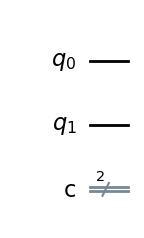

In [ ]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator # Changed import
from qiskit.visualization import plot_histogram


qc = QuantumCircuit(2, 2)
qc.draw('mpl')

## Add a Hadamard gate to create superposition
- Apply **Hadamard (H)** to qubit 0 **and** try applying **Pauli-X** or **Z**.
- Observe how different gates affect the Bloch sphere.

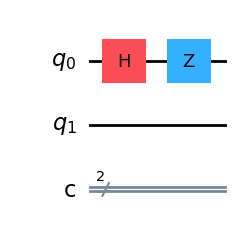

In [ ]:
qc.h(0)
qc.z(0)
qc.draw('mpl')

## Step 7: Visualize the statevector before measurement

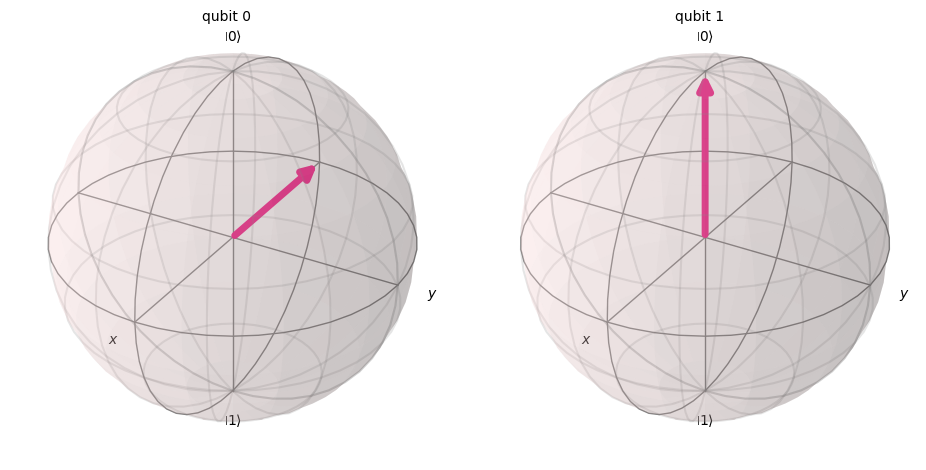

In [ ]:
from qiskit.visualization import plot_histogram, plot_bloch_multivector
from qiskit.quantum_info import Statevector
state = Statevector.from_instruction(qc)
plot_bloch_multivector(state)

## measure the qubits

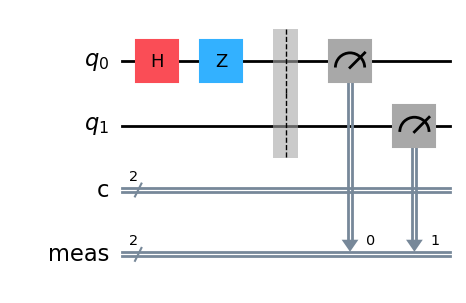

In [ ]:
# qc.measure(0, 1)    #measure qubit 0 to bit 0
# qc.measure(1, 1)  # optional second measurement
qc.measure_all()  # measure all qubits to all bits
qc.draw('mpl')

## Step 7: Visualize the statevector after measurement

This will give an error as the qubit collapses after measurement.

In [ ]:
state = Statevector.from_instruction(qc)
plot_bloch_multivector(state)

QiskitError: 'Cannot apply instruction with classical bits: measure'

We have to remove the measurements and then plot the Bloch Sphere

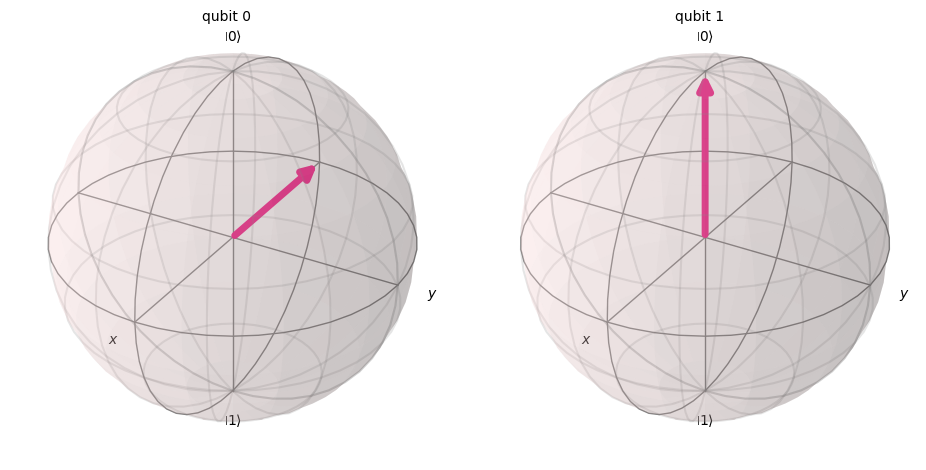

In [ ]:
qc_clean= qc.remove_final_measurements(inplace=False)
state = Statevector.from_instruction(qc_clean)
plot_bloch_multivector(state)

## Now execute the circuit and check the values

In [ ]:
sim = AerSimulator()
job = sim.run(qc, shots=1200).result()
result = job.get_counts()
print(result)

{'01 00': 592, '00 00': 608}


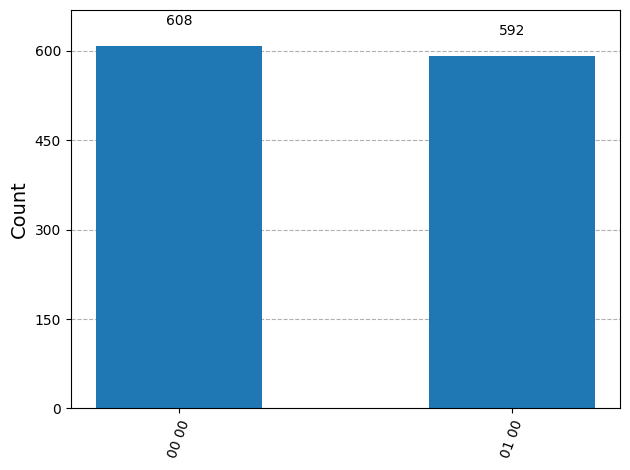

In [ ]:
plot_histogram(result)


## First circuit (Qiskit) — superposition and measurement


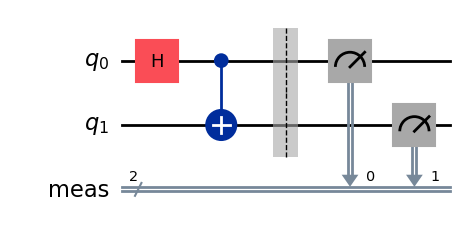

In [ ]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator # Changed import
from qiskit.visualization import plot_histogram

qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0,1)
qc.measure_all()
qc.draw('mpl')

In [ ]:
sim = AerSimulator()
job = sim.run(qc, shots=1000).result()
result = job.get_counts()
print(result)


{'00': 484, '11': 516}


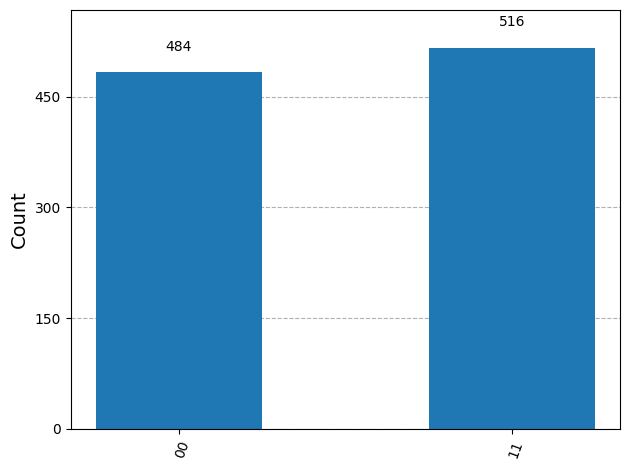

In [ ]:
plot_histogram(result)

## Assignment 1:  ##
- Create a three qubit circuit
- Apply Hadamard on first qubit
- apply cnot from first qubit to second
- apply cnot from first qubit to third
- plot the bloch sphere
- measure the circuits and plot results after executing on Aer simulator

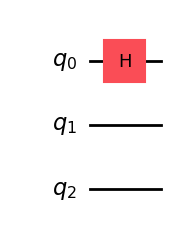

In [ ]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator # Changed import
from qiskit.visualization import plot_histogram
qc = QuantumCircuit(3)
qc.h(0)
qc.draw('mpl')

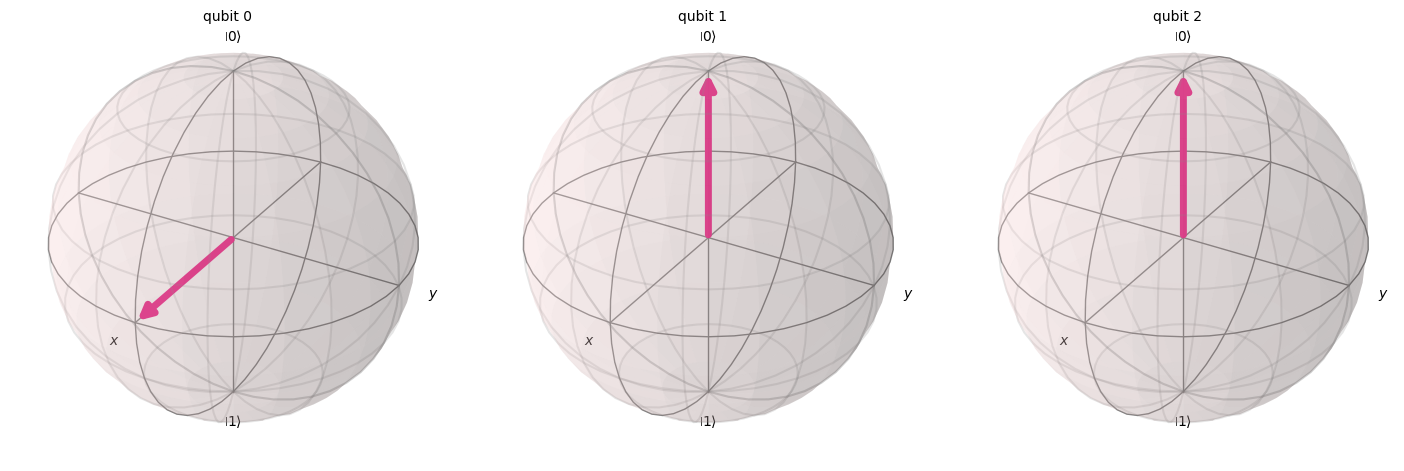

In [ ]:
from qiskit.visualization import plot_histogram, plot_bloch_multivector
from qiskit.quantum_info import Statevector
state = Statevector.from_instruction(qc)
plot_bloch_multivector(state)

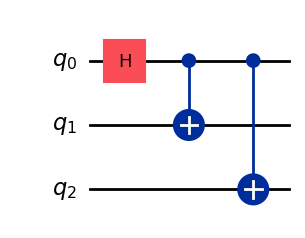

In [ ]:
qc.cx(0,1)
qc.cx(0,2)
qc.draw('mpl')

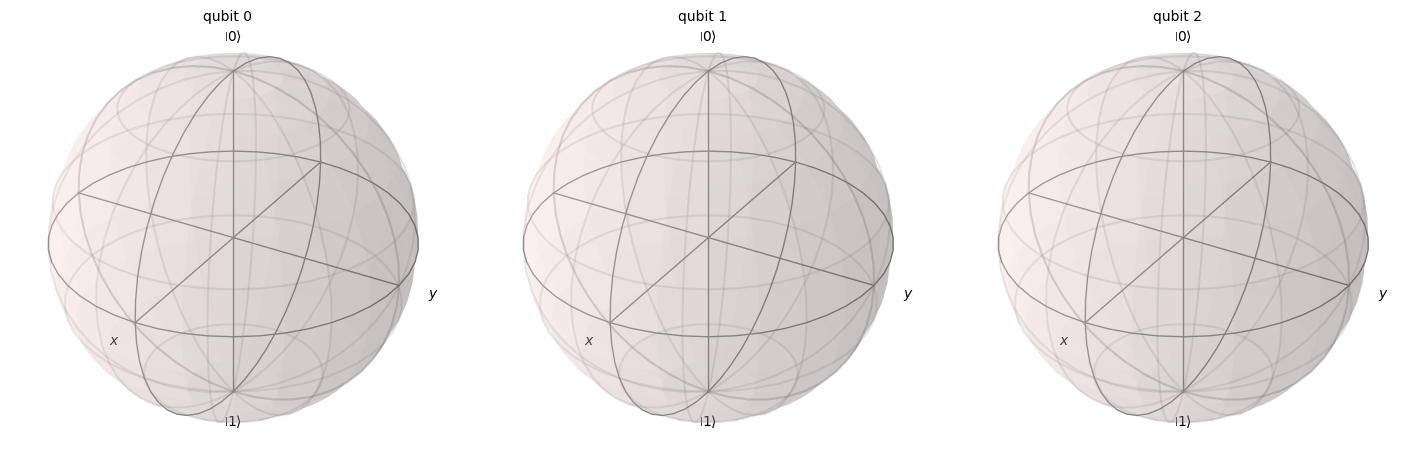

In [ ]:
from qiskit.visualization import plot_histogram, plot_bloch_multivector
from qiskit.quantum_info import Statevector
state = Statevector.from_instruction(qc)
plot_bloch_multivector(state)